# Intro to amortized Bayesian inference with BayesFlow

In this tutorial, we introduce the basics of amortized Bayesian inference by going through the basic components of Bayesian workflow with BayesFlow. 

By the end of this tutorial, you should be able to:

- Define a data-generating model as simulator for BayesFlow;
- Construct a basic amortized workflow with BayesFlow for neural posterior estimation; and
- Train the estimator for posterior estimation.

To demonstrate, we will simulate spline curves as an example, and train a neural posterior estimator that allows us to estimate the underlying parameters that govern how they are generated. 

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import keras
import bayesflow as bf

## 1. Forward Model Specification

### Spline: a simple math for smooth shapes

In general, a [spline](https://en.wikipedia.org/wiki/Spline_(mathematics)) is a mathematical function of a continuous curve that is constrained by a collection of points. Since it lets us describe a complex smooth shape with relatively minimal math, it becomes widely used to represent and control arbitrarily complex shapes in 3D modeling, computer graphics, and engineering analyses, especially in situations where where we want the geometries to be smooth.

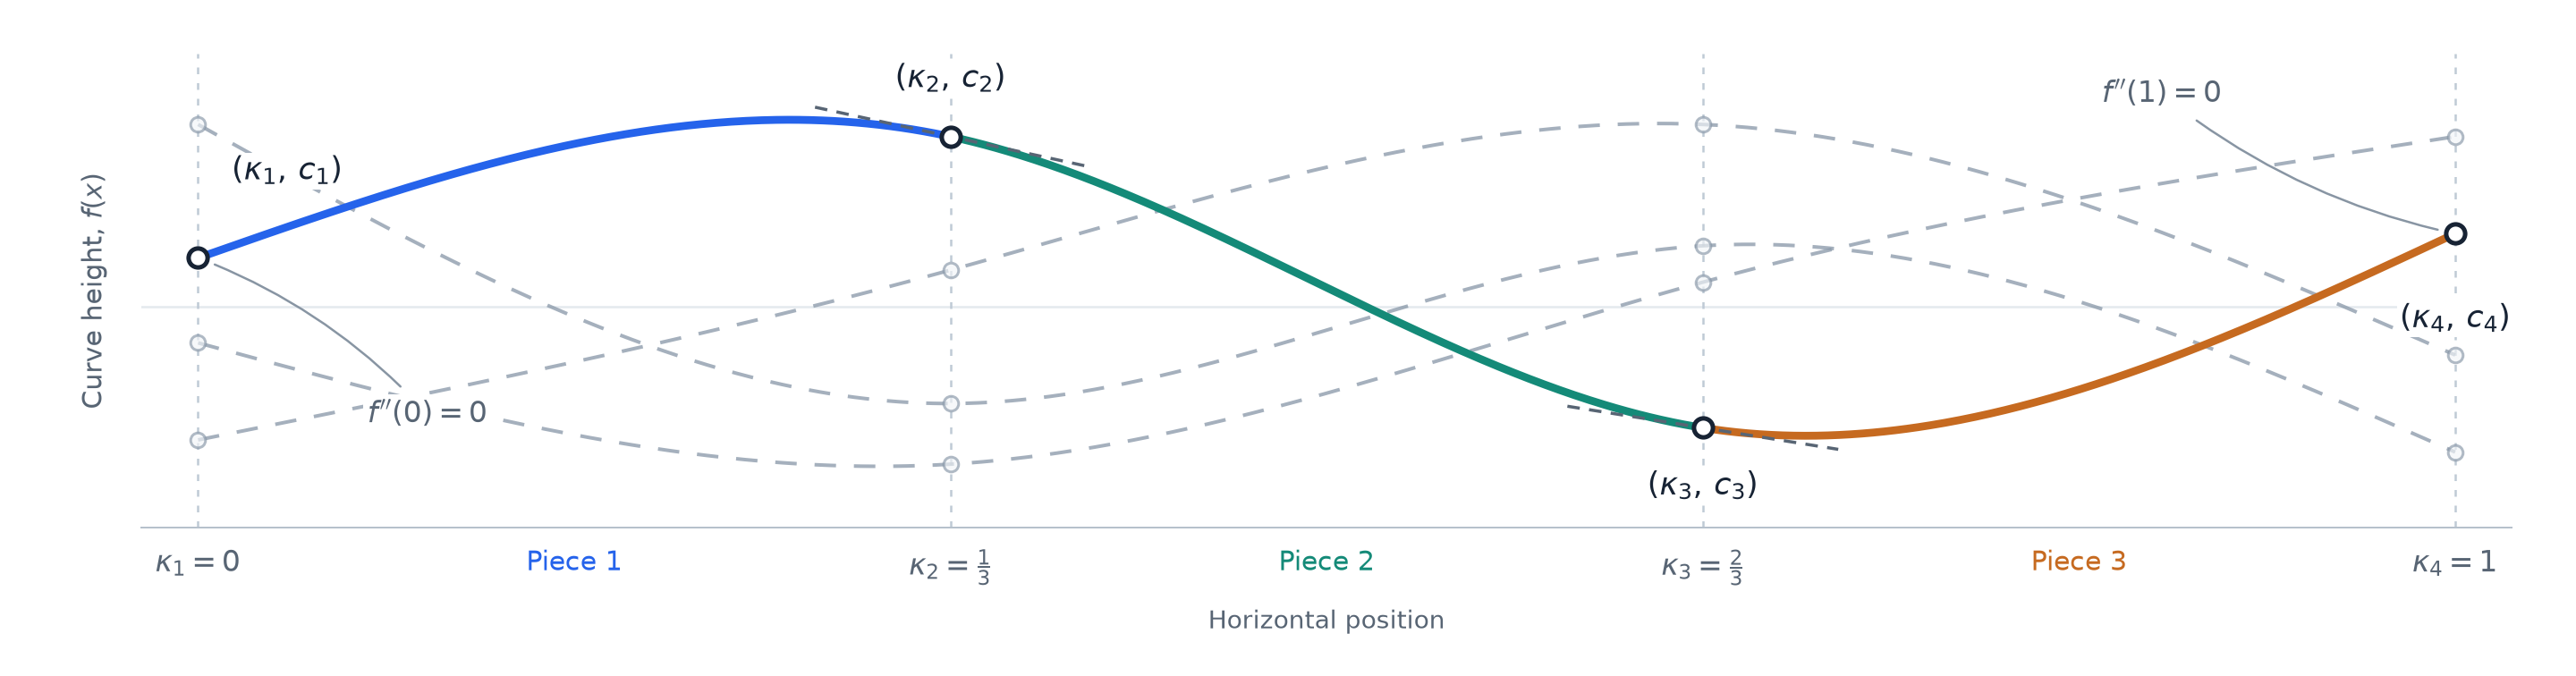

There are many different types of splines. One of them is the **natural cubic spline** (see the above image), which we use as our forward model. 

Let $\kappa_1<\cdots<\kappa_K$ be fixed knot locations and $c_1,\ldots,c_K$ the curve's heights at those knots. Between each pair of knots, the curve is a polynomial of degree at most three:

$$
f(x;c)=p_j(x)=\sum_{r=0}^{3}a_{jr}(x-\kappa_j)^r,
\qquad x\in[\kappa_j,\kappa_{j+1}],\quad j=1,\ldots,K-1.
$$

Each piece passes through its two endpoint heights,

$$
p_j(\kappa_j)=c_j,
\qquad
p_j(\kappa_{j+1})=c_{j+1}.
$$

At each interior knot, neighboring pieces have matching slopes and second
derivatives:

$$
p_{j-1}'(\kappa_j)=p_j'(\kappa_j),
\qquad
p_{j-1}''(\kappa_j)=p_j''(\kappa_j),
\qquad j=2,\ldots,K-1.
$$

The natural boundary conditions set the second derivative to zero at both ends:

$$
p_1''(\kappa_1)=0,
\qquad
p_{K-1}''(\kappa_K)=0.
$$

Together, these conditions determine the polynomial coefficients $a_{jr}$ from
the knot heights. We use $K=4$ knots at $(0,\tfrac13,\tfrac23,1)$, so the four
heights $c=(c_1,c_2,c_3,c_4)$ determine the entire curve and are the parameters
we will infer.


### Simulator

Our goal is to recover the four knot heights $c$ from the spline curve they
generate. We evaluate each curve at 200 equally spaced horizontal positions:

$$
x_i=\frac{i-1}{199},\qquad y_i=f(x_i;c),\qquad i=1,\ldots,200.
$$

These curve values are exact. Across datasets, the knot heights vary while
the knot locations and evaluation grid stay fixed.

In [ ]:
KNOTS = np.linspace(0.0, 1.0, 4)
N_KNOTS = len(KNOTS)
N_OBSERVATIONS = 200
PARAMETER_NAMES = [f"$c_{j + 1}$" for j in range(N_KNOTS)]
x_grid = np.linspace(0.0, 1.0, N_OBSERVATIONS)

`SciPy` has implemented `CubicSpline` as a readymade function for our simulator.

In [ ]:
from scipy.interpolate import CubicSpline


def simulate_spline(heights):
    """Evaluate a spline, or a batch of splines, on the fixed grid."""
    # Column j is the spline with height 1 at knot j and 0 at the other knots.
    basis = CubicSpline(KNOTS, np.eye(N_KNOTS), bc_type="natural")
    return np.asarray(heights) @ basis(x_grid).T

`simulate_spline` maps knot heights to a curve. Change one entry of
`example_heights` to see how the shape changes. Next, we will use a prior to
generate different sets of knot heights and their corresponding curves.

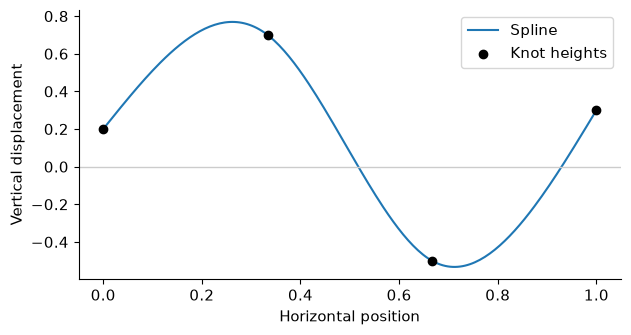

In [ ]:
example_heights = np.array([0.2, 0.7, -0.5, 0.3])

spline_values = simulate_spline(example_heights)
x_plot = np.linspace(0.0, 1.0, len(spline_values))

fig, ax = plt.subplots()
ax.plot(x_plot, spline_values, label="Spline")
ax.scatter(KNOTS, example_heights, color="black", zorder=3, label="Knot heights")
ax.axhline(0, color="0.8", linewidth=1)
ax.set(xlabel="Horizontal position", ylabel="Vertical displacement")
ax.legend()
plt.show()

## S2 · Prior specification

BayesFlow learns from parameters paired with the curves they generate. We
draw the parameters from independent Gaussian priors:

$$c_j\overset{\mathrm{iid}}\sim\mathcal N(0,\tau^2),\qquad \tau=0.5.$$

This centers the curves on the reference line and puts about 95% of each knot
height's prior probability between $-1$ and $1$. The spline makes nearby curve
values dependent even though the knot heights have independent priors.

The function below samples the heights, generates the curves, and returns
both in a dictionary. `bf.make_simulator` wraps it in BayesFlow's simulator
interface. With `is_batched=True`, one call generates a whole batch.

| Dictionary entry | Contents | Role in training |
|---|---|---|
| `heights` | Four generating knot heights per dataset | Parameters to infer |
| `observations` | 200 `(x, y)` points on each curve | Data to condition on |

`simulator.sample(8)` requests eight curves, each with its own knot heights.
Once the heights are drawn, the curve is deterministic.

In [ ]:
PRIOR_SD = 0.5

def simulate(batch_shape):
    """Draw knot heights and their noiseless curves."""
    heights = np.random.normal(0.0, PRIOR_SD, size=(*batch_shape, N_KNOTS))
    y = simulate_spline(heights)
    x = np.broadcast_to(x_grid, y.shape)
    observations = np.stack([x, y], axis=-1)
    return {
        "heights": heights.astype("float32"),
        "observations": observations.astype("float32"),
    }


simulator = bf.make_simulator(simulate, is_batched=True)
batch = simulator.sample(100)
print({name: values.shape for name, values in batch.items()})

{'heights': (100, 4), 'observations': (100, 200, 2)}


## S3 · Prior predictive and prior pushforward checks

Use `simulator.sample` to inspect the curves generated under the prior.
Here the curve is also the observable, so the prior pushforward and prior
predictive plots describe the same distribution.

BayesFlow will learn from these examples. Check whether their range and
shapes match the model we intended to specify.

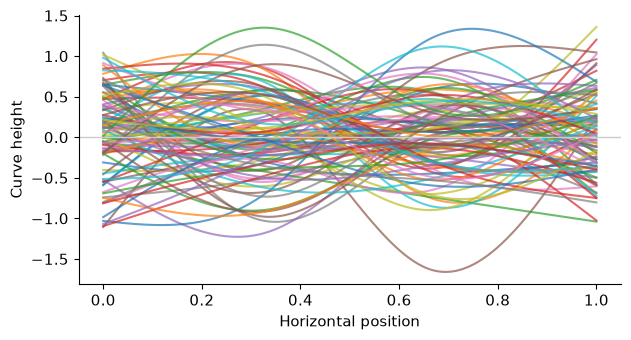

In [ ]:
fig, ax = plt.subplots()
for observations in batch["observations"]:
    ax.plot(*observations.T, alpha=0.7)

ax.axhline(0, color="0.8", linewidth=1)
ax.set(xlabel="Horizontal position", ylabel="Curve height")
plt.show()

**Check the simulator:** Which part of `simulate` makes the curves differ
across datasets? What changes if we call `simulate_spline` twice with the
same heights?

If you revise the prior, regenerate these curves before training. Keep the
chosen specification fixed through the remaining steps.

## Set aside a curve for inference

We will use one simulated curve as the observed dataset. It is separate from
training and validation. Its generating heights are retained for checking
recovery; only its `(x, y)` points are supplied when drawing neural samples.

A separate random generator keeps this curve fixed when the training budget
changes. Can you estimate the four knot heights visually?

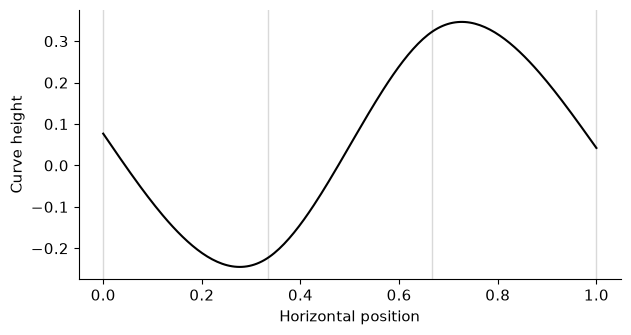

In [ ]:
observed = simulator.sample(1)
observations = observed["observations"][0]
x_observed, y_observed = observations.T

fig, ax = plt.subplots()
ax.plot(x_observed, y_observed, color="black")
for knot in KNOTS:
    ax.axvline(knot, color="0.85", linewidth=1, zorder=0)
ax.set(xlabel="Horizontal position", ylabel="Curve height")
plt.show()

## S4 · Computational faithfulness

A noiseless curve on this grid uniquely determines its four knot heights.
Its exact posterior is concentrated at that one parameter vector. We use
this version to practice BayesFlow's interfaces and check parameter recovery.
Spread in the neural draws reflects approximation error, rather than
uncertainty left by the observations.

We connect three components:

| Component | Job in this notebook |
|---|---|
| `SetTransformer` | Compress the 200 `(x, y)` pairs into 16 learned summaries. |
| `FlowMatching` | Learn a conditional generator for the knot heights. |
| `BasicWorkflow` | Connect simulation, data preparation, training, and sampling. |

A Set Transformer suits the data because row order is irrelevant. Each
vertical value must stay paired with its horizontal position.
`inference_variables=["heights"]` identifies the training targets, and
`summary_variables=["observations"]` identifies the inputs to summarize.
BayesFlow standardizes inputs and targets using training-data statistics.

The data shape is `(batch, 200, 2)` and the parameter shape is `(batch, 4)`.
We use the same grid and observation count throughout.

In [17]:
summary_network = bf.networks.SetTransformer()
inference_network = bf.networks.FlowMatching()

workflow = bf.BasicWorkflow(
    simulator=simulator,
    summary_network=summary_network,
    inference_network=inference_network,
    inference_variables=["heights"],
    summary_variables=["observations"],
    standardize=["inference_variables", "summary_variables"]
)

### Train with `fit_online`

`fit_online` generates fresh datasets for each training batch. Here,
`batch_size=32` means 64 datasets per update; `num_batches_per_epoch=100`
sets the updates per epoch. The validation datasets are generated once and
kept separate from training and the observed dataset.

The first epoch includes JAX compilation. The posterior checks below will
tell us whether this training budget is sufficient.

In [ ]:
history = workflow.fit_online(
    epochs=50,
    num_batches_per_epoch=100,
    batch_size=32,
    validation_data=100
)

INFO:bayesflow:Fitting on dataset instance of OnlineDataset.
INFO:bayesflow:Building on a test batch.


Epoch 1/50


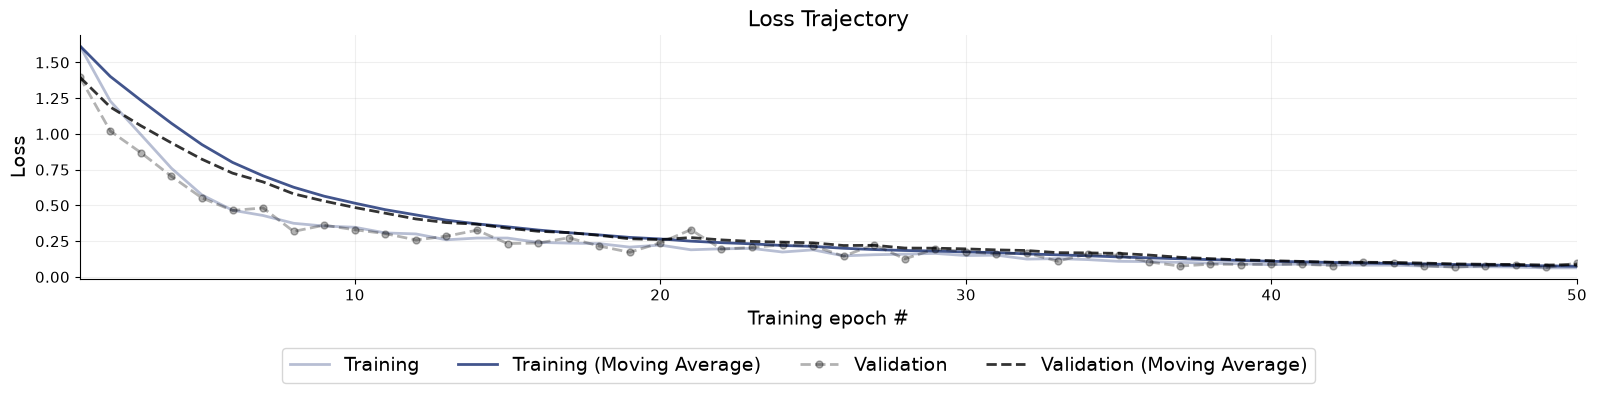

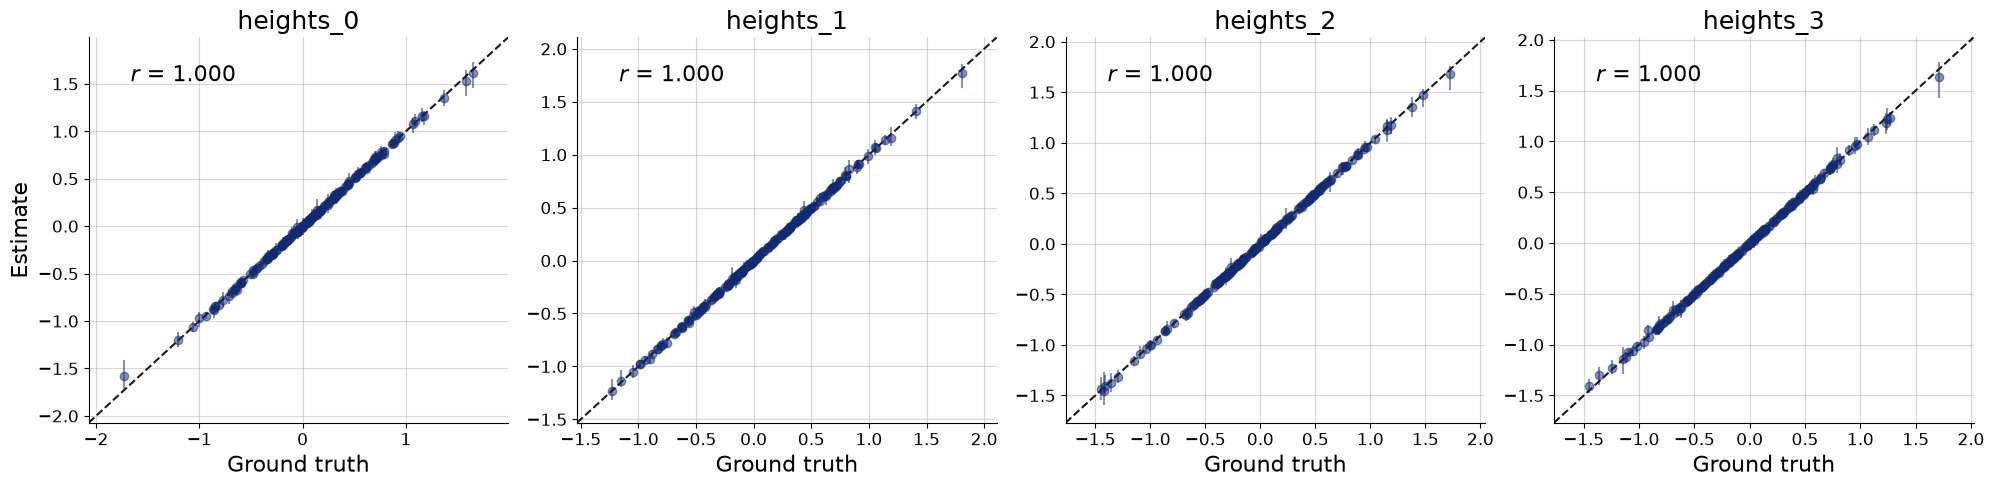

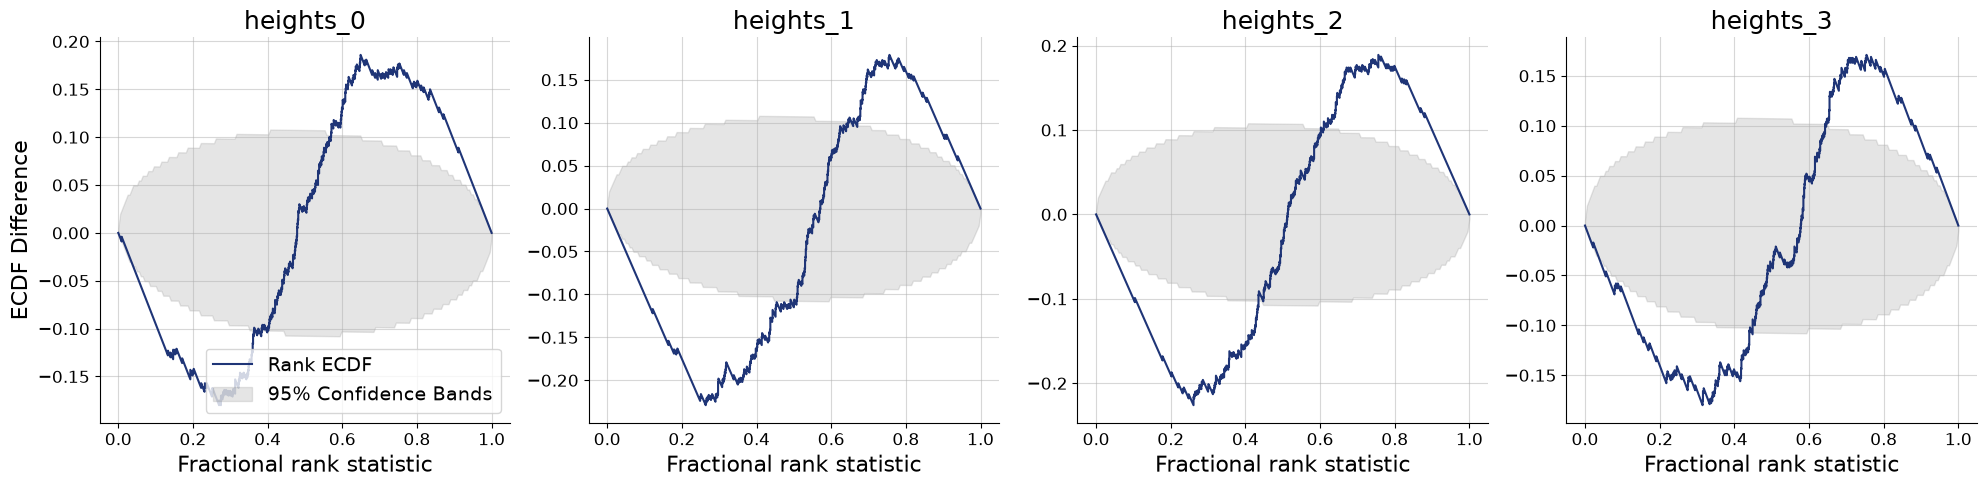

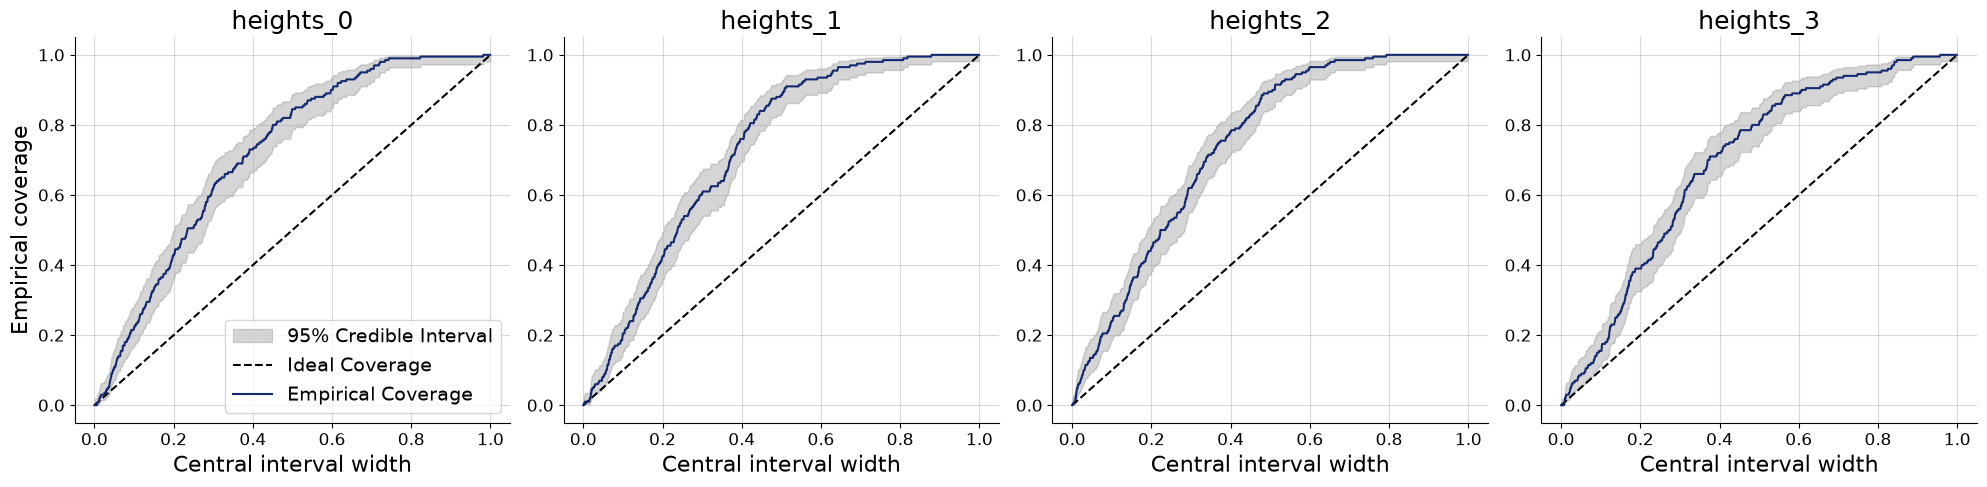

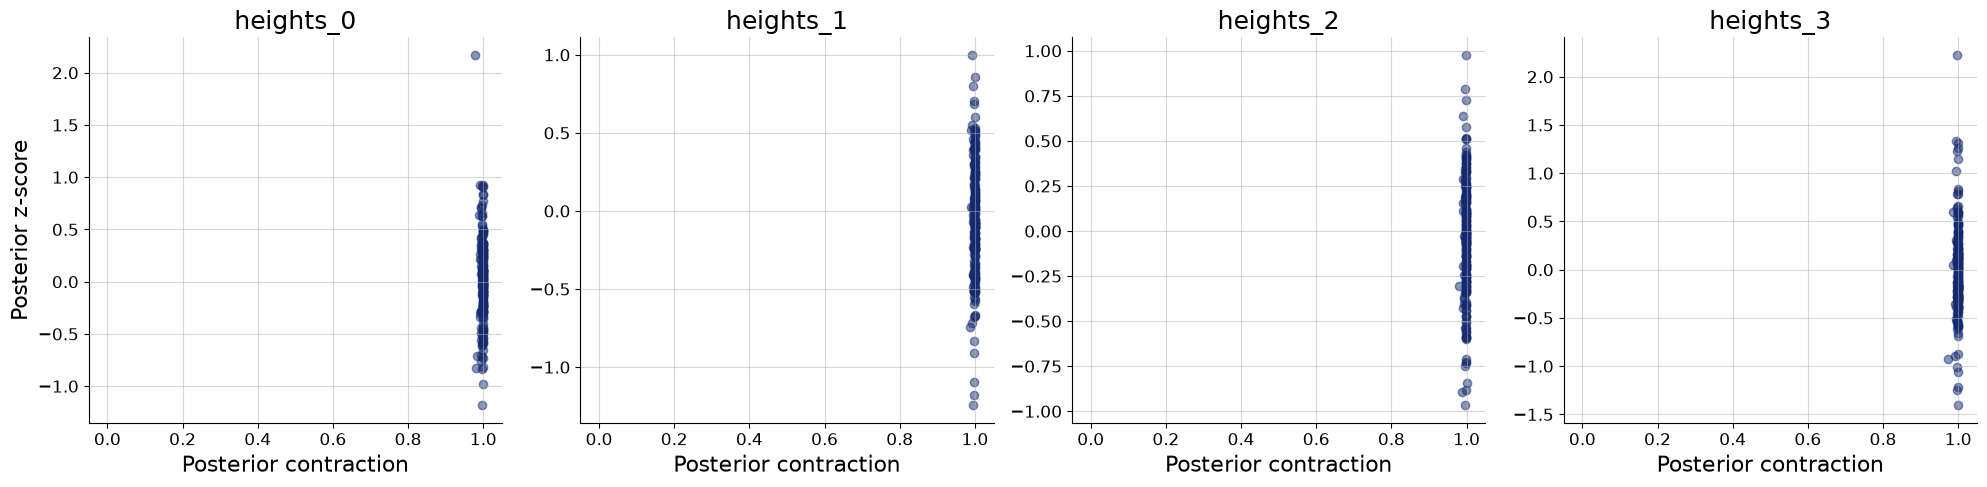

In [ ]:
figures = workflow.plot_default_diagnostics(test_data=100)

## S5 · Posterior retrodictive check

Use inferred knot heights as inputs to the forward model and compare the
resulting curves with the observed curve:

$$c^{(s)}\sim q_\phi(c\mid x,y),\qquad
 y_i^{\mathrm{rep},(s)}=f(x_i;c^{(s)}).$$

The blue lines below show 20 reconstructions. Their residuals should be close
to zero across the curve. Since the simulator is deterministic, any spread
or mismatch reflects the neural approximation.

In [ ]:
posterior_draws = workflow.sample(
    num_samples=20,
    conditions={"observations": observed["observations"]},
)["heights"][0]
replicated_curves = simulate_spline(posterior_draws)
x_observed, y_observed = observed["observations"][0].T

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(x_grid, replicated_curves.T, color="C0", alpha=0.2)
axes[0].plot(x_observed, y_observed, color="black", label="Observed curve")
axes[0].set(xlabel="Horizontal position", ylabel="Curve height")
axes[0].legend(fontsize=9)

axes[1].axhline(0, color="0.5", linewidth=1)
axes[1].plot(x_grid, (replicated_curves - y_observed).T, color="C0", alpha=0.2)
axes[1].set(xlabel="Horizontal position", ylabel="Reconstruction residual")
fig.tight_layout()
plt.show()

**Assess reconstruction:** Where do inferred curves depart from the observed
curve? Does a small error in the knot heights also give a small error across
the curve? A low training loss alone does not answer these questions.